# 03 V2 — GPU MLP: source-take quota, optional balancing & robust augmentation

Train 11 người, validate TDUY + DPHI; fresh final retrain 13 người; Test TRUONG chỉ ở bước cuối.

## 1 — Config GPU, reproducibility, candidates
`RUN_FINAL=True` chỉ đánh giá Test sau chọn best validation và retrain lại từ đầu. Không tuning theo Test.

In [ ]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
from pathlib import Path
import sys,json,zipfile,io,hashlib,re,random,platform,math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report
from tqdm.auto import tqdm
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError: pass
DRIVE_ROOT=Path('/content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu')
ROOT=Path(os.environ['POSEFORGE_ROOT']).expanduser() if os.environ.get('POSEFORGE_ROOT') else (
    DRIVE_ROOT if DRIVE_ROOT.is_dir() else next((p for p in (Path.cwd(),*Path.cwd().parents)
      if (p/'notebooks').is_dir() and (p/'shared').is_dir()),Path.cwd()))
ROOT=ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))

from shared.dataset_pipeline import file_sha256
from shared.pose_training import group_sample_epoch, augment_pose13_torch, usable_mask, dataset_output_root, refresh_review_zip, LABELS
from shared.mlp_model import PostureMLP, MODEL_REGISTRY

RAW_ZIP=Path(os.environ.get('POSEFORGE_ZIP',ROOT/'raw_dataset_zip/clean_raw_14_person_11n_pt_v001.zip'))
assert RAW_ZIP.is_file()
RAW_SHA=file_sha256(RAW_ZIP)
BASE=dataset_output_root(ROOT,RAW_SHA)
PROCESSED_ZIP=Path(os.environ.get('POSEFORGE_PROCESSED_ZIP',BASE/'processed/pose13_features.zip'))
assert PROCESSED_ZIP.is_file(), f'Run Notebook 02 first: {PROCESSED_ZIP}'

VAL_PEOPLE=['TDUY','DGD']
TEST_PEOPLE=['TRUONG']

RUN_FINAL=True
FINAL_CANDIDATE='auto'
OUTPUT_NAME='mlp_clean14'
CONFIRM_TOP_K=3     # Retest top 3 candidates with seeds 303 & 304, select by mean F1 across seeds
CONFIRM_SEEDS=(303,304)

DEVICE=torch.device(os.environ.get('POSEFORGE_DEVICE','cuda'))
assert DEVICE.type=='cpu' or torch.cuda.is_available(),'Enable Colab GPU or set POSEFORGE_DEVICE=cpu for smoke tests'
torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False
torch.use_deterministic_algorithms(True)

DEFAULT=dict(
    model='mlp_wide',
    seed=302,
    lr=1e-3,
    weight_decay=1e-3,
    batch_size=256,
    epochs=80,
    patience=12,
    dropout=.20,
    max_frames_per_source_camera=48,
    balance='none',
    class_weight='none',
    weight_cap=3.0,
    label_smoothing=0.0,
    flip_prob=0.0,
    jitter_prob=0.0,
    jitter_sigma=0.01,
    keypoint_dropout_prob=0.0,
    max_dropout_joints=2,
    confidence_perturb_prob=0.0,
    occlusion_prob=0.0
    )

# Independent ablations, then combinations. Train is cheap: validate broadly, confirm top K across seeds.
CANDIDATES=[
 {'name':'c01_small','model':'mlp_small','dropout':.10},
 {'name':'c02_base','model':'mlp_base','dropout':.15},
 {'name':'c03_wide'},
 {'name':'c04_balance_sqrt','balance':'sqrt_inverse'},
 {'name':'c05_balance_inverse','balance':'inverse'},
 {'name':'c06_weight_sqrt','class_weight':'sqrt_inverse'},
 {'name':'c07_smooth005','label_smoothing':.05},
 {'name':'c08_smooth010','label_smoothing':.10},
 {'name':'c09_flip','flip_prob':.5},
 {'name':'c10_jitter','jitter_prob':.3},
 {'name':'c11_flip_jitter','flip_prob':.5,'jitter_prob':.3},
 {'name':'c12_dropout','keypoint_dropout_prob':.10},
 {'name':'c13_occlusion','occlusion_prob':.10},
 {'name':'c14_confidence','confidence_perturb_prob':.15},
 {'name':'c15_robust','flip_prob':.5,'jitter_prob':.3,'keypoint_dropout_prob':.10},
 {'name':'c16_robust_smooth','flip_prob':.5,'jitter_prob':.3,
  'keypoint_dropout_prob':.10,'label_smoothing':.05},
 {'name':'c17_robust_balance','flip_prob':.5,'jitter_prob':.3,
  'keypoint_dropout_prob':.10,'balance':'sqrt_inverse'},
]

LABEL_NAMES=['Upright','Hunched','Head on desk','Leaning back','Side lean/turn','Hand raised']

assert re.fullmatch(r'[A-Za-z0-9_-]+',OUTPUT_NAME)
assert len(set(c['name'] for c in CANDIDATES))==len(CANDIDATES)

for candidate in CANDIDATES:
    cfg={**DEFAULT,**candidate}

    assert cfg['model'] in MODEL_REGISTRY and cfg['balance'] in ('none','sqrt_inverse','inverse')
    assert cfg['class_weight'] in ('none','sqrt_inverse','inverse')
    assert cfg['balance'] == 'none' or cfg['class_weight'] == 'none','Do not double balance by default'
    assert cfg['max_frames_per_source_camera'] > 0 and cfg['batch_size'] > 0 and cfg['epochs'] > 0 and cfg['patience'] > 0
    assert 0 <= cfg['label_smoothing'] < 1 and cfg['weight_cap'] >= 1

    for name in ('flip_prob','jitter_prob','keypoint_dropout_prob','confidence_perturb_prob','occlusion_prob'):
        assert 0<= cfg[name] <=1
    assert cfg['max_dropout_joints'] in (0,1,2) and cfg['jitter_sigma']>=0

print('Candidates:',[c['name'] for c in CANDIDATES], '| Device:',DEVICE)

Mounted at /content/drive
Candidates: ['c01_small', 'c02_base', 'c03_wide', 'c04_balance_sqrt', 'c05_balance_inverse', 'c06_weight_sqrt', 'c07_smooth005', 'c08_smooth010', 'c09_flip', 'c10_jitter', 'c11_flip_jitter', 'c12_dropout', 'c13_occlusion', 'c14_confidence', 'c15_robust', 'c16_robust_smooth', 'c17_robust_balance'] | Device: cuda


## 2 — Load processed ZIP once, data resident on GPU
Các frame 0–3 usable joints vẫn có trong ZIP/report nhưng không vào supervised train/eval.

In [ ]:
PROC_SHA = file_sha256(PROCESSED_ZIP)

# Stage ZIP locally in Colab when the processed ZIP lives on Google Drive.
if Path('/content').is_dir() and str(PROCESSED_ZIP.resolve()).startswith('/content/drive/'):
    local_zip = Path('/content') / f'processed_{PROC_SHA[:12]}.zip'

    if not local_zip.is_file() or file_sha256(local_zip) != PROC_SHA:
        with (
            PROCESSED_ZIP.open('rb') as src,
            local_zip.open('wb') as dst,
            tqdm(
                total=PROCESSED_ZIP.stat().st_size,
                unit='B',
                unit_scale=True,
                desc='Stage processed',
            ) as p,
        ):
            while (part := src.read(4 * 1024 * 1024)):
                dst.write(part)
                p.update(len(part))
else:
    local_zip = PROCESSED_ZIP

# Load and validate the frozen dataset metadata.
with zipfile.ZipFile(local_zip) as z:
    prefix = next(
        p[:-len('index.csv')]
        for p in z.namelist()
        if p.endswith('/index.csv')
    )

    index = pd.read_csv(io.BytesIO(z.read(prefix + 'index.csv')))
    contract = json.loads(z.read(prefix + 'feature_contract.json'))
    split_info = json.loads(z.read(prefix + 'split_manifest.json'))

    assert contract['version'] == 'pose13_xy_conf_mask_causal_v2'
    assert contract['shape_per_frame'] == [13, 4] and contract['flatten_dim'] == 52
    assert (
        contract['extractor'] == 'yolo11n-pose.pt'
        and contract['source_zip_sha256'] == RAW_SHA
    )
    assert split_info['source_zip_sha256'] == RAW_SHA
    assert (
        split_info['validation_people'] == sorted(VAL_PEOPLE)
        and split_info['test_people'] == sorted(TEST_PEOPLE)
    )
    assert split_info['strategy'] == 'subject_wise_frozen_v2'
    assert index.clip_id.is_unique and set(index.split) == {'train', 'val', 'test'}

    # Read one per-clip NPZ at a time and concatenate its frame features.
    X_parts = []
    Y_parts = []
    clips = []
    offset = 0

    for row in tqdm(
        index.itertuples(index=False),
        total=len(index),
        desc='Load 52 features',
    ):
        assert row.feature_path == f'features/{row.clip_id}.npz', 'Unexpected feature path'

        with np.load(
            io.BytesIO(z.read(prefix + row.feature_path)),
            allow_pickle=False,
        ) as f:
            x = f['x'].astype('float32')

        assert x.shape == (int(row.frames), 13, 4) and np.isfinite(x).all()
        assert np.isin(x[:, :, 3], (0., 1.)).all()
        assert int(usable_mask(x).sum()) == int(row.usable_frames)

        X_parts.append(x.reshape(-1, 52))
        Y_parts.append(np.full(len(x), int(row.label), dtype='int64'))
        clips.append(
            dict(
                clip_id=row.clip_id,
                person=row.person_id,
                camera=row.camera_id,
                label=int(row.label),
                split=row.split,
                source_group_id=row.source_group_id,
                source_take_id=row.source_take_id,
                start=offset,
                end=offset + len(x),
            )
        )
        offset += len(x)

# Build CPU arrays and the supervised-usable frame mask.
X = np.concatenate(X_parts)
Y = np.concatenate(Y_parts)
VALID = usable_mask(X.reshape(-1, 13, 4))

assert len(X) == int(index.frames.sum()) == 21996 and len(clips) == 206

# Keep full features/labels resident on the selected PyTorch device.
X_GPU = torch.from_numpy(X).to(DEVICE)
Y_GPU = torch.from_numpy(Y).to(DEVICE)

print(
    'Total:', len(X),
    '| Usable:', int(VALID.sum()),
    '| No pose / insufficient:', int((~VALID).sum()),
)


Stage processed:   0%|          | 0.00/7.74M [00:00<?, ?B/s]

Load 52 features:   0%|          | 0/206 [00:00<?, ?it/s]

Total: 21996 | Usable: 21987 | No pose / insufficient: 9


## 3 — Frozen split, independent-group quota

In [ ]:
# Split clip records according to the frozen person-wise partitions.
train = [c for c in clips if c['split'] == 'train']
val = [c for c in clips if c['split'] == 'val']
test = [c for c in clips if c['split'] == 'test']
final_train = train + val

# Verify subjects and source groups do not cross splits.
assert {c['person'] for c in train} == set(split_info['train_people'])
assert {c['person'] for c in val} == set(VAL_PEOPLE)
assert {c['person'] for c in test} == set(TEST_PEOPLE)
assert not (
    {c['source_group_id'] for c in train}
    & {c['source_group_id'] for c in val + test}
)

# Count usable frames per label in each split.
for split, subset in [('train', train), ('val', val), ('test', test)]:
    y = np.concatenate([
        Y[np.arange(c['start'], c['end'])[VALID[c['start']:c['end']]]]
        for c in subset
    ])

    assert set(y) == set(LABELS), f'{split} missing usable class'

    print(
        split,
        'people:', sorted({c['person'] for c in subset}),
        'eligible:', len(y),
        'by label:', np.bincount(y, minlength=6).tolist(),
    )

print('Source take quota 48/camera/epoch; segments share original source group.')


train people: ['CHANH', 'DPHI', 'HDUY', 'KIET', 'KNGUYEN', 'LM', 'MINHLE', 'MINHNG', 'PHU', 'QBAO', 'VMTRI'] eligible: 16940 by label: [2560, 2851, 2605, 2856, 3162, 2906]
val people: ['DGD', 'TDUY'] eligible: 4206 by label: [587, 1121, 1042, 396, 493, 567]
test people: ['TRUONG'] eligible: 841 by label: [144, 140, 129, 146, 128, 154]
Source take quota 48/camera/epoch; segments share original source group.


## 4 — Evaluation: frame, person-macro, camera, clip and ORIGINAL source-take

In [ ]:
def frame_ids(c):
    ids = np.arange(c['start'], c['end'], dtype='int64')
    return ids[VALID[ids]]


@torch.no_grad()
def predict(model, subset):
    model.eval()

    # 1. Keep only supervised-eligible frames from the requested clips.
    prepared = [(c, frame_ids(c)) for c in subset]
    prepared = [(c, idx) for c, idx in prepared if len(idx)]
    all_ids = np.concatenate([idx for c, idx in prepared])

    # 2. Run inference in chunks to avoid allocating one giant batch.
    probs = []
    for chunk in np.array_split(
        all_ids,
        max(1, math.ceil(len(all_ids) / 4096)),
    ):
        probs.append(
            model(X_GPU[torch.as_tensor(chunk, device=DEVICE)])
            .softmax(1)
            .cpu()
            .numpy()
        )

    p_all = np.concatenate(probs)

    # 3. Group predictions by frame, clip, and original source take.
    frames = []
    clip_rows = []
    source_bins = {}
    cursor = 0

    for c, ids in prepared:
        p = p_all[cursor:cursor + len(ids)]
        cursor += len(ids)
        yh = p.argmax(1)

        frames.extend(
            {
                'label': c['label'],
                'pred': int(v),
                'person': c['person'],
                'camera': c['camera'],
                'clip_id': c['clip_id'],
                'source_group_id': c['source_group_id'],
                'true_prob': float(row[c['label']]),
                'confidence': float(row.max()),
            }
            for v, row in zip(yh, p)
        )

        clip_rows.append(
            dict(
                label=c['label'],
                pred=int(p.mean(axis=0).argmax()),
                person=c['person'],
                camera=c['camera'],
                clip_id=c['clip_id'],
            )
        )

        key = c['source_group_id']
        if key not in source_bins:
            source_bins[key] = [[], c['label'], c['person']]
        source_bins[key][0].append((p.sum(axis=0), len(p)))

    src_rows = []
    for key, (pieces, y, person) in source_bins.items():
        ps = sum(v for v, n in pieces) / sum(n for v, n in pieces)
        src_rows.append(
            dict(
                source_group_id=key,
                label=y,
                pred=int(ps.argmax()),
                person=person,
            )
        )

    return (
        pd.DataFrame(frames),
        pd.DataFrame(clip_rows),
        pd.DataFrame(src_rows),
    )


def macro_score(df):
    if df.empty:
        return 0.0
    return float(
        f1_score(
            df.label,
            df.pred,
            labels=list(LABELS),
            average='macro',
            zero_division=0,
        )
    )


def calibration_error(fr, bins=10):
    conf = fr.confidence.to_numpy()
    correct = (fr.label.to_numpy() == fr.pred.to_numpy()).astype(float)
    boundaries = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for i in range(bins):
        member = (conf >= boundaries[i]) & (
            (conf <= boundaries[i + 1])
            if i == bins - 1
            else (conf < boundaries[i + 1])
        )
        if member.any():
            ece += member.mean() * abs(
                correct[member].mean() - conf[member].mean()
            )

    return float(ece)


def scoring(result):
    fr, cl, src = result
    per_subject = {
        p: macro_score(g)
        for p, g in fr.groupby('person')
    }

    return dict(
        frame_macro_f1=macro_score(fr),
        subject_macro_f1=float(np.mean(list(per_subject.values()))),
        clip_macro_f1=macro_score(cl),
        source_macro_f1=macro_score(src),
        frame_accuracy=float(accuracy_score(fr.label, fr.pred)),
        min_subject_macro_f1=float(min(per_subject.values())),
        calibration_ece=calibration_error(fr),
        n_frames=int(len(fr)),
        n_source_takes=int(len(src)),
        per_subject_f1=per_subject,
        nll=float(
            -np.log(np.clip(fr.true_prob.to_numpy(), 1e-9, 1)).mean()
        ),
    )


def export_eval(result, folder):
    folder.mkdir(parents=True, exist_ok=True)
    fr, cl, src = result
    scores = scoring(result)

    # Numerical reports and predictions.
    (folder / 'metrics.json').write_text(json.dumps(scores, indent=2))
    src.to_csv(folder / 'source_take_predictions.csv', index=False)
    cl.to_csv(folder / 'clip_predictions.csv', index=False)

    pd.DataFrame(
        classification_report(
            fr.label,
            fr.pred,
            labels=list(LABELS),
            target_names=LABEL_NAMES,
            output_dict=True,
            zero_division=0,
        )
    ).T.to_csv(folder / 'per_class.csv')

    groups = []
    for field in ('person', 'camera'):
        for name, grp in fr.groupby(field):
            groups.append(
                dict(
                    group_type=field,
                    group=name,
                    frames=len(grp),
                    macro_f1=macro_score(grp),
                )
            )
    pd.DataFrame(groups).to_csv(folder / 'group_metrics.csv', index=False)

    # Confusion-matrix figure.
    cm = confusion_matrix(fr.label, fr.pred, labels=list(LABELS))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')

    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha='center', va='center')

    ax.set(
        xticks=list(LABELS),
        yticks=list(LABELS),
        xlabel='Pred',
        ylabel='True',
        title='Confusion matrix',
    )
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(folder / 'confusion_matrix.png', dpi=140)
    plt.close(fig)

    return scores


## 5 — Train loop: sampling + optional balancing/smoothing/augmentation

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_loss(cfg, subset):
    if cfg['class_weight'] == 'none':
        weight = None
    else:
        # Effective group-quotad frames; no raw frame-count domination.
        inds = group_sample_epoch(
            subset,
            VALID,
            cfg['max_frames_per_source_camera'],
            cfg['seed'],
            epoch=1,
        )
        counts = np.bincount(Y[inds], minlength=6).astype('float64')
        assert (counts > 0).all()

        power = .5 if cfg['class_weight'] == 'sqrt_inverse' else 1.0
        weights = (counts.mean() / counts) ** power
        weights = np.clip(weights, 1 / cfg['weight_cap'], cfg['weight_cap'])
        weights /= weights.mean()
        weight = torch.as_tensor(weights, dtype=torch.float32, device=DEVICE)

    return nn.CrossEntropyLoss(
        weight=weight,
        label_smoothing=cfg['label_smoothing'],
    )


def train_epoch(model, optimizer, loss_fn, cfg, subset, epoch, seed):
    model.train()
    ids = group_sample_epoch(
        subset,
        VALID,
        cfg['max_frames_per_source_camera'],
        seed,
        epoch,
        balance=cfg['balance'],
    )
    if not len(ids):
        raise ValueError('No eligible frames')

    aug_rng = torch.Generator(device=DEVICE).manual_seed(
        seed * 1_000_003 + epoch * 1009 + 17
    )
    losses = []

    for chunk in np.array_split(
        ids,
        max(1, math.ceil(len(ids) / cfg['batch_size'])),
    ):
        idx = torch.as_tensor(chunk, device=DEVICE)
        xb = augment_pose13_torch(X_GPU[idx], cfg, aug_rng)
        loss = loss_fn(model(xb), Y_GPU[idx])

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.detach().cpu()))

    return float(np.mean(losses)), len(ids)


def checkpoint(model, cfg, epoch, people, stage, metrics):
    return dict(
        model_state_dict={
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        model_name=cfg['model'],
        model_config=cfg,
        feature_contract=contract,
        label_names=LABEL_NAMES,
        source_processed_zip_sha256=PROC_SHA,
        source_raw_zip_sha256=RAW_SHA,
        train_people=sorted(people),
        epoch=int(epoch),
        stage=stage,
        metrics=metrics,
    )


def run_candidate(cfg, folder):
    folder.mkdir(parents=True, exist_ok=False)
    (folder / 'config.json').write_text(json.dumps(cfg, indent=2))

    set_seed(cfg['seed'])
    model = PostureMLP(cfg['model'], dropout=cfg['dropout']).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg['lr'],
        weight_decay=cfg['weight_decay'],
    )
    loss_fn = make_loss(cfg, train)

    best_key = None
    best_epoch = 0
    stale = 0
    history = []

    for epoch in tqdm(range(1, cfg['epochs'] + 1), desc=cfg['name']):
        loss, n_samples = train_epoch(
            model, optimizer, loss_fn, cfg, train, epoch, cfg['seed']
        )
        result = predict(model, val)
        metrics = scoring(result)
        key = (
            metrics['subject_macro_f1'],
            metrics['min_subject_macro_f1'],
            metrics['source_macro_f1'],
            -metrics['nll'],
        )
        history.append(
            dict(
                epoch=epoch,
                train_batch_loss=loss,
                train_samples=n_samples,
                val_subject_f1=metrics['subject_macro_f1'],
                val_frame_f1=metrics['frame_macro_f1'],
                val_source_f1=metrics['source_macro_f1'],
                val_nll=metrics['nll'],
                val_ece=metrics['calibration_ece'],
            )
        )

        if best_key is None or key > best_key:
            best_key = key
            best_epoch = epoch
            stale = 0
            torch.save(
                checkpoint(
                    model, cfg, epoch,
                    split_info['train_people'],
                    'selection', metrics,
                ),
                folder / 'best.pt',
            )
        else:
            stale += 1

        if stale >= cfg['patience']:
            break

    history_df = pd.DataFrame(history)
    history_df.to_csv(folder / 'history.csv', index=False)

    # Candidate learning curves.
    fig, ax = plt.subplots(2, 2, figsize=(10, 6))
    ax[0, 0].plot(history_df.epoch, history_df.train_batch_loss)
    ax[0, 0].set(
        xlabel='Epoch', ylabel='Cross entropy', title='Training loss'
    )
    ax[0, 1].plot(history_df.epoch, history_df.val_nll)
    ax[0, 1].set(
        xlabel='Epoch', ylabel='Negative log-likelihood',
        title='Validation loss',
    )
    ax[1, 0].plot(
        history_df.epoch, history_df.val_subject_f1,
        label='Mean person Macro-F1',
    )
    ax[1, 0].plot(
        history_df.epoch, history_df.val_source_f1,
        label='Source Macro-F1', alpha=.75,
    )
    ax[1, 0].axvline(
        best_epoch, color='gray', linestyle='--', linewidth=1
    )
    ax[1, 0].set(
        xlabel='Epoch', ylabel='F1', title='Validation F1', ylim=(0, 1)
    )
    ax[1, 0].legend(fontsize=8)
    ax[1, 1].plot(history_df.epoch, history_df.val_ece)
    ax[1, 1].set(
        xlabel='Epoch', ylabel='ECE',
        title='Validation calibration error',
    )
    fig.tight_layout()
    fig.savefig(folder / 'learning_curves.png', dpi=140)
    plt.close(fig)

    saved = torch.load(folder / 'best.pt', map_location='cpu', weights_only=True)
    model.load_state_dict(saved['model_state_dict'])
    best = export_eval(predict(model, val), folder / 'validation')

    summary = dict(
        candidate=cfg['name'],
        model=cfg['model'],
        best_epoch=best_epoch,
        epochs_ran=len(history),
        **{
            ('val_' + k): v
            for k, v in best.items()
            if k != 'per_subject_f1'
        },
        val_per_subject_f1=best['per_subject_f1'],
    )
    (folder / 'summary.json').write_text(json.dumps(summary, indent=2))
    return summary


## 6 — Train candidates, compare validation; never inspect Test here

c01_small:   0%|          | 0/80 [00:00<?, ?it/s]

c02_base:   0%|          | 0/80 [00:00<?, ?it/s]

c03_wide:   0%|          | 0/80 [00:00<?, ?it/s]

c04_balance_sqrt:   0%|          | 0/80 [00:00<?, ?it/s]

c05_balance_inverse:   0%|          | 0/80 [00:00<?, ?it/s]

c06_weight_sqrt:   0%|          | 0/80 [00:00<?, ?it/s]

... (8 outputs left out)

c15_robust:   0%|          | 0/80 [00:00<?, ?it/s]

c16_robust_smooth:   0%|          | 0/80 [00:00<?, ?it/s]

c17_robust_balance:   0%|          | 0/80 [00:00<?, ?it/s]

,candidate,model,best_epoch,val_subject_macro_f1,val_min_subject_macro_f1,val_source_macro_f1,val_nll
12,c13_occlusion,mlp_wide,9,0.981799,0.966347,1.0,0.132299
13,c14_confidence,mlp_wide,9,0.981703,0.966154,1.0,0.128076
3,c04_balance_sqrt,mlp_wide,8,0.981703,0.966154,1.0,0.134239
16,c17_robust_balance,mlp_wide,4,0.980882,0.967729,1.0,0.219698
8,c09_flip,mlp_wide,5,0.978913,0.963370,1.0,0.191075
10,c11_flip_jitter,mlp_wide,5,0.978288,0.960954,1.0,0.184377
15,c16_robust_smooth,mlp_wide,5,0.978252,0.963589,1.0,0.239031
2,c03_wide,mlp_wide,9,0.977935,0.958619,1.0,0.142019
9,c10_jitter,mlp_wide,9,0.977676,0.958101,1.0,0.139968
5,c06_weight_sqrt,mlp_wide,9,0.977416,0.957582,1.0,0.141729


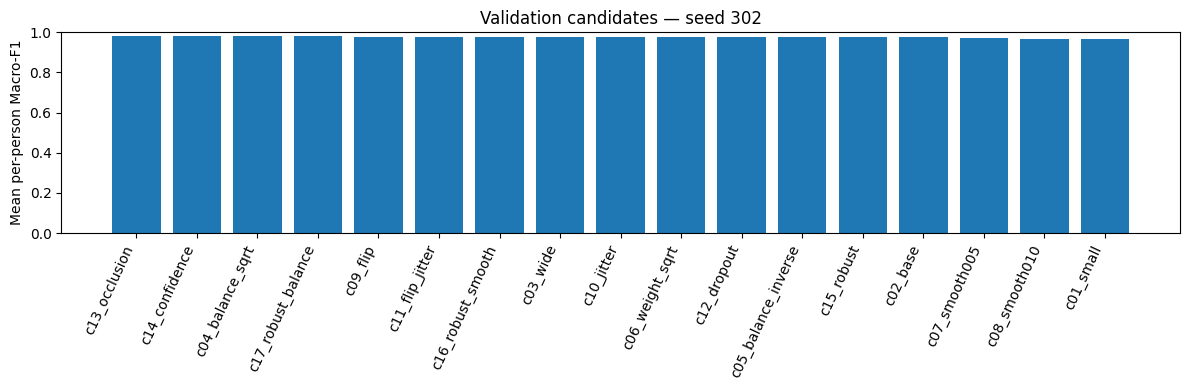

c13_occlusion:   0%|          | 0/80 [00:00<?, ?it/s]

c13_occlusion:   0%|          | 0/80 [00:00<?, ?it/s]

c14_confidence:   0%|          | 0/80 [00:00<?, ?it/s]

c14_confidence:   0%|          | 0/80 [00:00<?, ?it/s]

c04_balance_sqrt:   0%|          | 0/80 [00:00<?, ?it/s]

c04_balance_sqrt:   0%|          | 0/80 [00:00<?, ?it/s]

,candidate,mean_f1,std_f1,min_person_f1,mean_source_f1,median_epoch
1,c13_occlusion,0.983373,0.001960,0.970023,1.0,9.0
2,c14_confidence,0.983083,0.001625,0.969675,1.0,9.0
0,c04_balance_sqrt,0.978749,0.005172,0.961545,1.0,8.0


[PASS] Candidates and 3-seed confirmation; frozen Test untouched; best: c13_occlusion


In [ ]:
# 1. Create a new versioned experiment folder.
run_base = BASE / 'training'
run_base.mkdir(exist_ok=True)

for version in range(1, 10000):
    RUN_DIR = run_base / f'{OUTPUT_NAME}_v{version:03d}'
    try:
        RUN_DIR.mkdir(exist_ok=False)
        break
    except FileExistsError:
        pass
else:
    raise RuntimeError('Version exhausted')

# 2. Record feature, experiment, and environment metadata.
(RUN_DIR / 'feature_contract.json').write_text(
    json.dumps(contract, indent=2)
)
(RUN_DIR / 'experiment_config.json').write_text(
    json.dumps(
        dict(
            dataset_name=RAW_ZIP.name,
            raw_sha256=RAW_SHA,
            processed_sha256=PROC_SHA,
            split=split_info,
            defaults=DEFAULT,
            candidates=CANDIDATES,
            ranking='mean_subject_macro_f1 > source_macro_f1 > nll',
            run_final=RUN_FINAL,
        ),
        indent=2,
    )
)
(RUN_DIR / 'environment.json').write_text(
    json.dumps(
        dict(
            python=platform.python_version(),
            torch=torch.__version__,
            device=str(DEVICE),
            gpu=(
                torch.cuda.get_device_name()
                if DEVICE.type == 'cuda'
                else 'cpu'
            ),
        ),
        indent=2,
    )
)

# 3. Train candidates and rank them using validation only.
results = []
for variant in CANDIDATES:
    cfg = {**DEFAULT, **variant}
    results.append(
        run_candidate(cfg, RUN_DIR / 'candidates' / cfg['name'])
    )

comparison = pd.DataFrame(results).sort_values(
    [
        'val_subject_macro_f1',
        'val_min_subject_macro_f1',
        'val_source_macro_f1',
        'val_nll',
        'candidate',
    ],
    ascending=[False, False, False, True, True],
    kind='mergesort',
)
comparison.to_csv(RUN_DIR / 'comparison.csv', index=False)
display(
    comparison[
        [
            'candidate', 'model', 'best_epoch',
            'val_subject_macro_f1', 'val_min_subject_macro_f1',
            'val_source_macro_f1', 'val_nll',
        ]
    ]
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(comparison.candidate, comparison.val_subject_macro_f1)
ax.set(
    ylabel='Mean per-person Macro-F1',
    title='Validation candidates — seed 302',
    ylim=(0, 1),
)
plt.xticks(rotation=65, ha='right')
plt.tight_layout()
plt.savefig(RUN_DIR / 'candidate_comparison.png', dpi=140)
plt.show()
plt.close()

# 4. Confirm the leading candidates across seeds (VAL only; never TEST).
repeat_records = []
shortlist = comparison.head(min(CONFIRM_TOP_K, len(comparison))).candidate.tolist()

for name in shortlist:
    base_row = next(r for r in results if r['candidate'] == name)
    repeat_records.append(
        dict(
            candidate=name,
            seed=DEFAULT['seed'],
            f1=base_row['val_subject_macro_f1'],
            min_person_f1=base_row['val_min_subject_macro_f1'],
            source_f1=base_row['val_source_macro_f1'],
            best_epoch=base_row['best_epoch'],
        )
    )

    variant = next(c for c in CANDIDATES if c['name'] == name)
    for seed in CONFIRM_SEEDS:
        cfg = {**DEFAULT, **variant, 'seed': seed}
        row = run_candidate(
            cfg, RUN_DIR / 'confirmation' / name / f'seed_{seed}'
        )
        repeat_records.append(
            dict(
                candidate=name,
                seed=seed,
                f1=row['val_subject_macro_f1'],
                min_person_f1=row['val_min_subject_macro_f1'],
                source_f1=row['val_source_macro_f1'],
                best_epoch=row['best_epoch'],
            )
        )

confirmed = pd.DataFrame(repeat_records)
confirmed.to_csv(RUN_DIR / 'seed_confirmation.csv', index=False)

# 5. Aggregate seed stability, select the top candidate, and fix final epochs.
ranking = confirmed.groupby('candidate').agg(
    mean_f1=('f1', 'mean'),
    std_f1=('f1', 'std'),
    min_person_f1=('min_person_f1', 'mean'),
    mean_source_f1=('source_f1', 'mean'),
    median_epoch=('best_epoch', 'median'),
).reset_index()

ranking = ranking.sort_values(
    ['mean_f1', 'min_person_f1', 'mean_source_f1', 'std_f1', 'candidate'],
    ascending=[False, False, False, True, True],
    kind='mergesort',
)
ranking.to_csv(RUN_DIR / 'confirmed_ranking.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(
    ranking.candidate,
    ranking.mean_f1,
    yerr=ranking.std_f1.fillna(0),
    capsize=4,
)
ax.set(
    ylabel='Validation F1 (mean ± SD)',
    title='Top candidates across 3 seeds',
    ylim=(0, 1),
)
plt.xticks(rotation=15)
plt.tight_layout()
fig.savefig(RUN_DIR / 'seed_stability.png', dpi=140)
plt.close(fig)

selected_name = str(ranking.iloc[0].candidate)
selection = dict(
    selected=selected_name,
    top_k=shortlist,
    seeds=[DEFAULT['seed'], *CONFIRM_SEEDS],
    selection='highest mean person Macro-F1 on validation across 3 seeds; min-person tie break',
    final_epochs=max(1, int(round(float(ranking.iloc[0].median_epoch)))),
)
(RUN_DIR / 'selection.json').write_text(json.dumps(selection, indent=2))

display(ranking)
print(
    '[PASS] Candidates and 3-seed confirmation; '
    'frozen Test untouched; best:',
    selected_name,
)


## 7 — Final: fresh model trained on 13 non-test people; held-out TRUONG test once

In [ ]:
final_summary = None

if RUN_FINAL:
    # 1. Choose the final model and number of training epochs.
    name = selected_name if FINAL_CANDIDATE == 'auto' else FINAL_CANDIDATE
    assert name in [c['name'] for c in CANDIDATES]

    selected = next(c for c in CANDIDATES if c['name'] == name)
    cfg = {**DEFAULT, **selected}
    chosen = next(r for r in results if r['candidate'] == name)
    epochs = (
        selection['final_epochs']
        if name == selected_name
        else int(chosen['best_epoch'])
    )
    assert epochs >= 1

    # 2. Fresh model: retrain on all non-test people.
    final_dir = RUN_DIR / 'final'
    final_dir.mkdir(exist_ok=False)
    set_seed(cfg['seed'] + 10000)

    model = PostureMLP(cfg['model'], dropout=cfg['dropout']).to(DEVICE)
    opt = torch.optim.AdamW(
        model.parameters(),
        lr=cfg['lr'],
        weight_decay=cfg['weight_decay'],
    )
    loss_fn = make_loss(cfg, final_train)
    history = []

    for epoch in tqdm(
        range(1, epochs + 1),
        desc='Final retrain / 13 people',
    ):
        loss, n = train_epoch(
            model, opt, loss_fn, cfg, final_train,
            epoch, cfg['seed'] + 10000,
        )
        history.append(
            dict(epoch=epoch, train_loss=loss, train_samples=n)
        )

    pd.DataFrame(history).to_csv(final_dir / 'history.csv', index=False)

    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(
        [r['epoch'] for r in history],
        [r['train_loss'] for r in history],
    )
    ax.set(
        xlabel='Epoch',
        ylabel='Training CE',
        title='Final retrain — 13 people',
    )
    fig.tight_layout()
    fig.savefig(final_dir / 'learning_curve.png', dpi=140)
    plt.close(fig)

    # 3. Only this line touches held-out Test predictions,
    #    after model selection and retrain.
    test_result = predict(model, test)
    test_metrics = export_eval(test_result, final_dir / 'test')

    # 4. Save final results and the final trained model.
    final_summary = dict(
        candidate=name,
        selection_basis='validation_subject_macro_f1',
        epochs=epochs,
        train_people=sorted(set(c['person'] for c in final_train)),
        test_people=sorted(TEST_PEOPLE),
        test_independent=True,
        test_metrics=test_metrics,
    )
    (final_dir / 'final_summary.json').write_text(
        json.dumps(final_summary, indent=2)
    )
    torch.save(
        checkpoint(
            model, cfg, epochs,
            final_summary['train_people'], 'final', test_metrics,
        ),
        final_dir / 'model_final.pt',
    )

    display(pd.DataFrame([test_metrics]))
    print('[PASS] Independent TRUONG test evaluated ONCE:', final_dir)
else:
    print('No Test access: enable RUN_FINAL when ready')


Final retrain / 13 people:   0%|          | 0/9 [00:00<?, ?it/s]

,frame_macro_f1,subject_macro_f1,clip_macro_f1,source_macro_f1,frame_accuracy,min_subject_macro_f1,calibration_ece,n_frames,n_source_takes,per_subject_f1,nll
0,0.99179,0.99179,1.0,1.0,0.991677,0.99179,0.064301,841,6,{'TRUONG': 0.9917899026396558},0.109187


[PASS] Independent TRUONG test evaluated ONCE: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/training/mlp_clean14_v001/final


## 8 — Refresh one review.zip + export final_model_bundle.zip
Không nhét dataset hoặc trained weights vào review ZIP; output versioned.

In [8]:
# Only three archives across the whole pipeline:
# (1) processed/pose13_features.zip; (2) review.zip; (3) final_model_bundle.zip
bundle=None
if RUN_FINAL:
    bundle=RUN_DIR/'final_model_bundle.zip'
    with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
        z.write(RUN_DIR/'final/model_final.pt','model_final.pt')
        z.write(RUN_DIR/'final/final_summary.json','final_summary.json')
        z.write(RUN_DIR/'feature_contract.json','feature_contract.json')
        z.write(RUN_DIR/'experiment_config.json','experiment_config.json')
        z.write(ROOT/'shared/mlp_model.py','shared/mlp_model.py')
    with zipfile.ZipFile(bundle) as z:assert z.testzip() is None
    (RUN_DIR/'final/model_final.pt').unlink()   # one deploy weight copy, inside bundle
review=refresh_review_zip(BASE,RUN_DIR)
print('RUN:',RUN_DIR,'\nREVIEW:',review,'\nBUNDLE:',bundle)


RUN: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/training/mlp_clean14_v001 
REVIEW: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/review.zip 
BUNDLE: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/training/mlp_clean14_v001/final_model_bundle.zip
